# EDA de ULB (Credit Card Fraud)

Este análisis se hizo con el proposito de entender el dataset con el que vamos a trabajar. Para armar el contexto para TabPFN necesitamos entender el conjunto de datos para realizar una limpieza en caso de que sea necesario (filas repetidas, datos faltantes, etc.).

Miramos únicamente la partición train de la semilla 0. Val y test no se usan para ningún gráfico ni cálculo. Ya que si mirásemos toda la tabla para decidir cosas (por ejemplo, qué variables parecen buenas), estaríamos contribuyendo a la fuga de datos.

Cómo está ordenado:
1) Balance de clases
2) `Amount` y `Time` por clase
3) Duplicados
4) `V1`–`V28`

Al correr, las figuras se guardan en `reports/figures/`.

## 0. Preparación

In [29]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

from tpf.data.loaders import load_ulb
from tpf.data.splits import load_split, make_split, row_hashes, split_path
from tpf.paths import DATA_SPLITS, REPORTS

SEED = 0
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 110
COLORES = {"legítima": "tab:blue", "fraude": "tab:red"}

### Cargar los datos y quedarnos solo con train

In [30]:
X_all, y_all = load_ulb()

if split_path("ulb", SEED).exists():
    parts = load_split("ulb", SEED)
else:
    parts = make_split(y_all, SEED)

idx_train = parts["train"]
X = X_all.iloc[idx_train].reset_index(drop=True)
y = y_all.iloc[idx_train].reset_index(drop=True)
etiqueta = y.map({0: "legítima", 1: "fraude"})  # nombre legible de cada clase

del X_all, y_all, parts  # se eliminan val y test

assert X.shape == (170_884, 30), X.shape
assert int(y.sum()) == 295, int(y.sum())
print(f"Train (semilla {SEED}): {X.shape[0]:,} filas x {X.shape[1]} columnas")
print("Columnas:", list(X.columns[:3]), "...", list(X.columns[-2:]))
print("Valores faltantes:", int(X.isna().sum().sum()))

Train (semilla 0): 170,884 filas x 30 columnas
Columnas: ['Time', 'V1', 'V2'] ... ['V28', 'Amount']
Valores faltantes: 0


## 1. Balance de clases

In [31]:
n = len(y)
n_pos = int(y.sum())
n_neg = n - n_pos
pi = n_pos / n  # proporción de fraude en train

balance = pd.DataFrame(
    {"filas": [n_neg, n_pos], "porcentaje": [100 * n_neg / n, 100 * pi]},
    index=["legítima (0)", "fraude (1)"],
)
display(balance)

,filas,porcentaje
legítima (0),170589,99.827
fraude (1),295,0.173


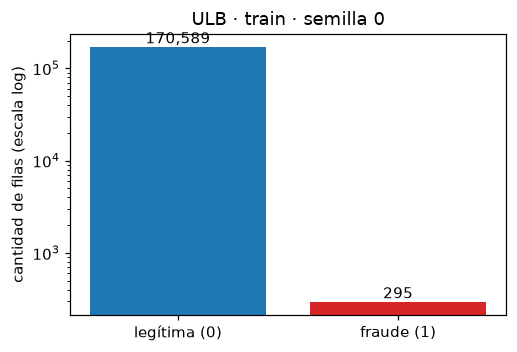

In [32]:
fig, ax = plt.subplots(figsize=(4.8, 3.3))
valores = [n_neg, n_pos]
ax.bar(["legítima (0)", "fraude (1)"], valores, color=[COLORES["legítima"], COLORES["fraude"]])
ax.set_yscale("log")
ax.set_ylabel("cantidad de filas (escala log)")
ax.set_title("ULB · train · semilla 0")
for i, v in enumerate(valores):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda_ulb_balance.png")
plt.show()

Podemos ver un gran desbalance entre ambas clases haciendo que un modelo que siempre responde no fraude acierte 99.83% y detecta 0 de los 295 fraudes.

### ¿Cuántos fraudes entran en un contexto?

Esto es lo que más nos importa para el resto del trabajo. Con muestreo Uniform (al azar, sin mirar la clase) se espera `m × proporción de fraude`. Con Balanced pedimos mitad y mitad, pero en train solo hay 295 fraudes,
así que no se puede llegar a la mitad: usamos todos los fraudes y completamos con legítimas ("Balanced capado").

In [33]:
filas = []
for m in (1_000, 5_000, 10_000):
    filas.append(
        {
            "m (tamaño del contexto)": m,
            "fraudes esperados (Uniform)": m * pi,
            "P(contexto sin ningún fraude)": (1 - pi) ** m,  # aproximación binomial
            "fraudes en Balanced capado": min(n_pos, m // 2),
            "% de fraude en Balanced capado": 100 * min(n_pos, m // 2) / m,
        }
    )
tabla_contexto = pd.DataFrame(filas).set_index("m (tamaño del contexto)")
display(tabla_contexto)

,fraudes esperados (Uniform),P(contexto sin ningún fraude),fraudes en Balanced capado,% de fraude en Balanced capado
m (tamaño del contexto),,,,
1000,1.726,0.178,295,29.500
5000,8.632,0.000,295,5.900
10000,17.263,0.000,295,2.950


Con muestreo al azar y m = 1.000 esperamos solo 1,7 fraudes, y el 17,8 % de las veces ninguno. Con m = 5.000 y 10.000 esperamos 8,6 y 17,3. Balanced no puede llegar a 50/50, así que usa los 295 fraudes y completa con normales: queda con 29,5 %, 5,9 % y 2,95 % de fraude.

## 2. `Amount` y `Time` por clase

`Amount` es el monto de la transacción. `Time` son los segundos transcurridos desde la primera transacción del dataset. Son las únicas dos columnas que no están anonimizadas.

In [34]:
tabla_amount = X.groupby(etiqueta)["Amount"].describe(percentiles=[0.5, 0.9, 0.99])
display(tabla_amount)

monto_cero = (X["Amount"] == 0).groupby(etiqueta).mean() * 100
print("Porcentaje de transacciones con Amount = 0:")
print(monto_cero.round(2).to_string())

,count,mean,std,min,50%,90%,99%,max
Class,,,,,,,,
fraude,295.000,119.501,251.722,0.000,11.000,343.044,"1,229.130","2,125.870"
legítima,"170,589.000",88.025,242.307,0.000,22.020,202.000,"1,006.982","19,656.530"


Porcentaje de transacciones con Amount = 0:
Class
fraude     4.070
legítima   0.630


El monto solo no separa las clases. El fraude tiene más montos muy chicos (mediana menor) y una cola media más pesada (p90 mayor).

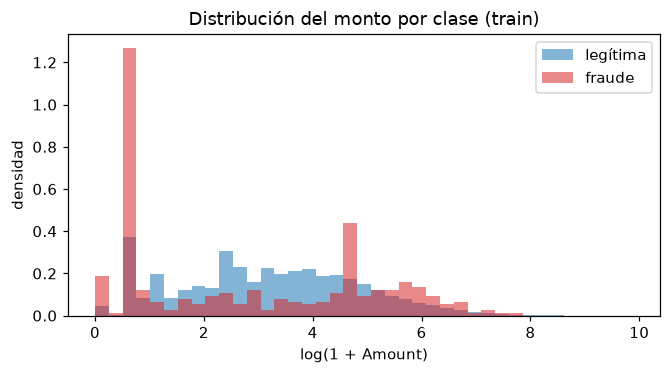

In [35]:
log_amount = np.log1p(X["Amount"])
bins = np.linspace(0, log_amount.max(), 40)

fig, ax = plt.subplots(figsize=(6.2, 3.5))
for clase, color in COLORES.items():
    ax.hist(
        log_amount[etiqueta == clase], bins=bins, density=True, alpha=0.55, color=color, label=clase
    )
ax.set_xlabel("log(1 + Amount)")
ax.set_ylabel("densidad")
ax.set_title("Distribución del monto por clase (train)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda_ulb_amount.png")
plt.show()

Los montos tienen muchos valores chicos y pocos altos, así que graficamos log(1 + Amount). 
Cada histograma está normalizado por clase si no, el fraude se plasmaria insignificante frente a las legítimas.

Time va de 0.0 h a 48.0 h


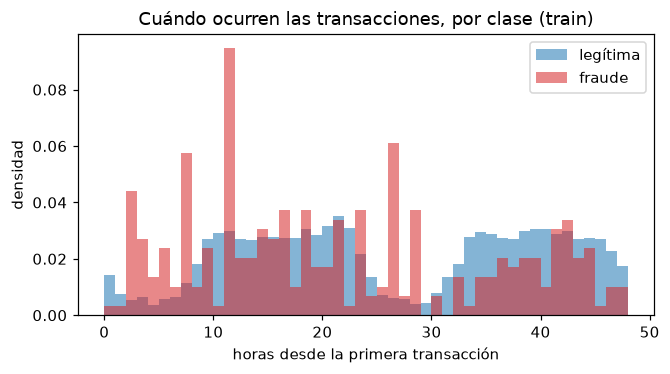

Fraudes por franja horaria relativa: mínimo 3, máximo 32, promedio 12.3


In [36]:
horas = X["Time"] / 3600
print(f"Time va de {horas.min():.1f} h a {horas.max():.1f} h")

fig, ax = plt.subplots(figsize=(6.2, 3.5))
bins_h = np.linspace(0, horas.max(), 49)
for clase, color in COLORES.items():
    ax.hist(
        horas[etiqueta == clase], bins=bins_h, density=True, alpha=0.55, color=color, label=clase
    )
ax.set_xlabel("horas desde la primera transacción")
ax.set_ylabel("densidad")
ax.set_title("Cuándo ocurren las transacciones, por clase (train)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda_ulb_time.png")
plt.show()

hora_rel = (X["Time"] // 3600 % 24).astype(int)
fraudes_por_hora = y.groupby(hora_rel).sum()
print(
    f"Fraudes por franja horaria relativa: mínimo {fraudes_por_hora.min()}, "
    f"máximo {fraudes_por_hora.max()}, promedio {fraudes_por_hora.mean():.1f}"
)

## 3. Duplicados

Acá buscamos filas iguales en las 30 columnas. Este análisis es imporante por dos motivos:
(1) si una fila repetida cae en el contexto, ocupa lugar sin aportar información nueva.
(2) si una copia está en train y otra en val/test, la evaluación sale mejor de lo que debería.

In [37]:
h = row_hashes(X)
d = pd.DataFrame({"h": h, "y": y.to_numpy()})

es_repetida = d["h"].duplicated(
    keep="first"
)  # Busca duplicados e indica cuáles no son la primera aparición.
n_dup = int(es_repetida.sum())
n_dup_pos = int(d.loc[es_repetida, "y"].sum())

# Busca contradicciones: filas idénticas con etiquetas distintas.
grupos = d.groupby("h")["y"].agg(["size", "nunique"])
n_conflictos = int((grupos["nunique"] > 1).sum())
max_copias = int(grupos["size"].max())

print(f"Filas repetidas en train: {n_dup:,} ({100 * n_dup / n:.2f}% de train)")
print(f"  de ellas, fraudes: {n_dup_pos} (de {n_pos} fraudes en train)")
print(f"Máximo de copias de una misma fila: {max_copias}")
print(f"Grupos con etiquetas contradictorias: {n_conflictos}")


ruta_manifiesto = DATA_SPLITS / "MANIFEST_splits.json"
if ruta_manifiesto.exists():
    manifiesto = json.loads(ruta_manifiesto.read_text(encoding="utf-8"))
    info = manifiesto["datasets"]["ulb"]
    cruz = info["by_seed"][str(SEED)]["dup_cross"]
    print(
        f"\nSegún el manifiesto (semilla {SEED}): "
        f"filas de val con copia exacta en train = {cruz['val']}, "
        f"de test = {cruz['test']}"
    )
    print(
        f"Duplicados en toda la tabla: {info['dup_global']['n_dup_rows']} filas "
        f"({info['dup_global']['n_dup_pos']} fraudes)"
    )

Filas repetidas en train: 465 (0.27% de train)
  de ellas, fraudes: 10 (de 295 fraudes en train)
Máximo de copias de una misma fila: 11
Grupos con etiquetas contradictorias: 0

Según el manifiesto (semilla 0): filas de val con copia exacta en train = 244, de test = 267
Duplicados en toda la tabla: 1081 filas (19 fraudes)


Lo relevante es que el 3,4 % de los fraudes de train (10 de 295) son copias, contra 0,27 % en el total. Eso pesa más en Balanced y NearMiss, que toman todos los positivos, y puede inflar un poco el recall.

## 4. `V1`–`V28`

Ahora estudiamos las columnas anonimizadas (resultado de un PCA hecho por quienes publicaron el dataset).
Nos interesa medir cuanto sapara cada una a las dos clases.
Usamos el AUC de una sola variable: si usáramos solo esa columna como "puntaje de fraude",
¿qué tan bien ordenaría los fraudes por encima de las legítimas? 0,5 = no separa nada; cerca de 1 (o de 0)
= separa mucho (menor que 0,5 significa que el fraude tiende a valores bajos de esa columna).

,AUC (1 variable),"distancia a 0,5"
V14,0.046,0.454
V4,0.935,0.435
V12,0.066,0.434
V11,0.916,0.416
V10,0.088,0.412
V3,0.094,0.406
V7,0.144,0.356
V16,0.144,0.356


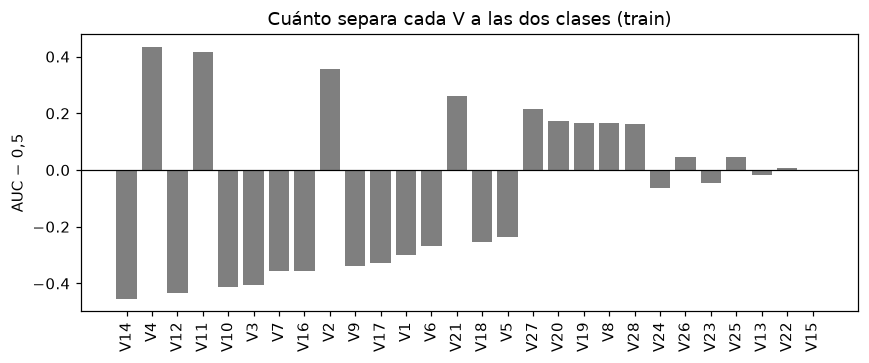

In [38]:
V = [f"V{i}" for i in range(1, 29)]
auc_uni = pd.Series({c: roc_auc_score(y, X[c]) for c in V})

# Tomamos las 8 variables más separadas
sep = pd.DataFrame({"AUC (1 variable)": auc_uni, "distancia a 0,5": (auc_uni - 0.5).abs()})
sep = sep.sort_values("distancia a 0,5", ascending=False)
display(sep.head(8))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(sep.index, sep["AUC (1 variable)"] - 0.5, color="tab:gray")
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("AUC − 0,5")
ax.set_title("Cuánto separa cada V a las dos clases (train)")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda_ulb_v_auc.png")
plt.show()

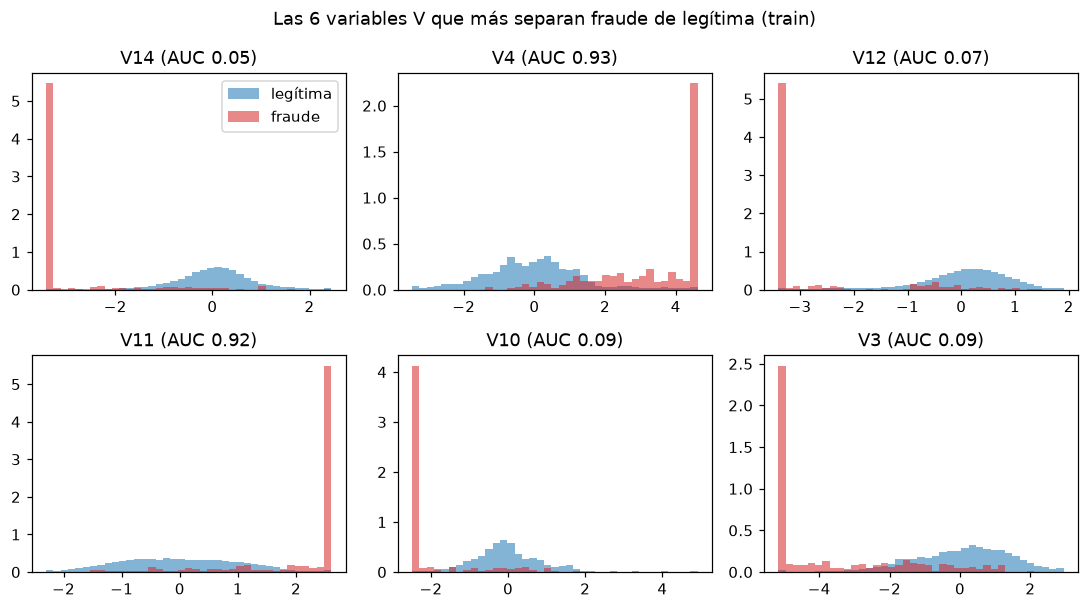

In [39]:
# Las 6 variables que más separan, comparadas por clase.
top6 = list(sep.index[:6])
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
for ax, c in zip(axes.ravel(), top6, strict=False):
    lo, hi = X[c].quantile([0.005, 0.995])
    bins_v = np.linspace(lo, hi, 40)
    for clase, color in COLORES.items():
        ax.hist(
            X.loc[etiqueta == clase, c].clip(lo, hi),
            bins=bins_v,
            density=True,
            alpha=0.55,
            color=color,
            label=clase,
        )
    ax.set_title(f"{c} (AUC {auc_uni[c]:.2f})")
axes[0, 0].legend()
fig.suptitle("Las 6 variables V que más separan fraude de legítima (train)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_eda_ulb_v_top6.png")
plt.show()

In [40]:
# Calculamos la correlación entre las V.
corr = X[V].corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
max_corr = float(corr.max())
print(f"Máxima correlación absoluta entre dos columnas V distintas: {max_corr:.3f}")
print("\nDesvío estándar de las V:")
print(X[V].std().round(2).to_string())

Máxima correlación absoluta entre dos columnas V distintas: 0.037

Desvío estándar de las V:
V1    1.950
V2    1.650
V3    1.510
V4    1.410
V5    1.350
V6    1.320
V7    1.210
V8    1.190
V9    1.100
V10   1.080
V11   1.020
V12   1.000
V13   0.990
V14   0.960
V15   0.920
V16   0.880
V17   0.850
V18   0.840
V19   0.810
V20   0.760
V21   0.740
V22   0.720
V23   0.640
V24   0.610
V25   0.520
V26   0.480
V27   0.400
V28   0.330


- Los AUC más alejados de 0,5 son V14 = 0,046, V4 = 0,935, V12 = 0,066, V11 = 0,916 y V10 = 0,088.
- AUC < 0,5 significa que el fraude toma valores bajos, y > 0,5 que toma valores altos. Invertidos, V14 da 0,95, V4 0,94 y V12 0,93, es decir, señal muy fuerte.
- La correlación máxima entre V es 0,037, así que son casi independientes, como corresponde a un PCA. Los desvíos van de 1,95 a 0,33.
- La señal está en pocas columnas. Con contextos de ~2 fraudes, TabPFN tiene muy poco para aprenderla, y eso refuerza la pregunta del TPF.